# TP5 - Inducción electromagnética

**Materia:** Electricidad y Magnetismo

**Integrantes:**
* Fernanda Perez
* Tomas Aragusuku
* Jonathan Gomez
* Carla Rocca

## 1. Objetivo

El objetivo de este trabajo es:
1. Partiendo de la ley de Faraday-Lenz, $\varepsilon = -\dfrac{\Delta\Phi}{\Delta t}$, deducir la fuerza electromotriz que se induce en una bobina chica ubicada en el centro de una bobina grande por la que circula una corriente alterna, y llegar a una expresión de la forma $\varepsilon(t) = k\,\sin(\omega t)$.
2. Calcular la amplitud $k$ con datos de referencia para el cálculo (bobina grande: $N = 200$ vueltas, $r = 0,1\,m$, con $I = 100\,mA$ y $f = 1\,kHz$; bobina chica: $N_s = 400$ vueltas, diámetro interno $21,2\,mm$ y externo $33\,mm$) y graficar la corriente y la fem inducida en función del tiempo.
3. Analizar la validez de las aproximaciones usadas y cómo depende la fem de la frecuencia, como referencia para contrastar con una experiencia real.
4. Dejar planteada la experiencia prevista y lo que se esperaba observar en ella.

> **Nota:** la experiencia no pudo realizarse. Por indicación del docente, se entrega la parte teórica. Este informe **no contiene mediciones**, y la parte práctica se presenta sin valores numéricos.

## 2. Materiales y montaje previstos

Los materiales que se iban a utilizar son:

* Generador de señales (fuente de corriente alterna).
* Bobina grande de $N$ vueltas y radio $r$.
* Bobina chica de $N_s$ vueltas y radio promedio $b$.
* Resistencia $R$.
* Osciloscopio de dos canales.
* Cables de conexión.

El montaje previsto tiene dos circuitos, que **no están conectados entre sí**: la señal llega a la bobina chica únicamente por inducción.

```
Generador ── bobina grande ── R ── vuelve al generador
                  ┆ campo magnético variable
             bobina chica (en el centro de la grande)

CH1 del osciloscopio: tensión en R  →  I = V_R / R
CH2 del osciloscopio: fem inducida en la bobina chica
```

La resistencia permite conocer la corriente de la bobina grande, ya que su tensión es proporcional a la corriente y está en fase con ella.

## 3. Introducción teórica

> Esta sección es puramente teórica: **no se midió nada**. Los valores usados son datos de referencia para el cálculo, y los resultados son predicciones para contrastar con una experiencia real.

### Ley de Faraday-Lenz

Cuando el flujo magnético $\Phi$ que atraviesa un circuito cambia con el tiempo, en el circuito se induce una **fuerza electromotriz** (fem):

$$\varepsilon = -\frac{\Delta\Phi}{\Delta t} \quad\longrightarrow\quad \varepsilon = -\frac{d\Phi}{dt}$$

donde el flujo es la cantidad de campo magnético que "atraviesa" la superficie del circuito. Para un campo $B$ uniforme y perpendicular a una superficie de área $A$:

$$\Phi = B\,A$$

Si el circuito es una bobina de $N_s$ vueltas, el mismo flujo atraviesa cada una de ellas, y las fem de todas las vueltas se suman: el flujo total es $N_s$ veces el de una vuelta.

El signo menos es la **ley de Lenz**: la fem inducida tiene el sentido que haría circular una corriente cuyo campo se **opone** al cambio de flujo que la produjo.

### Modelo teórico: bobina grande y bobina chica en su centro

Se considera una **bobina grande** de $N = 200$ vueltas y radio $r = 0,1\,m$, por la que circula una corriente alterna de amplitud $I_0 = 100\,mA$ y frecuencia $f = 1\,kHz$:

$$I(t) = I_0\cos(\omega t), \qquad \omega = 2\pi f$$

En su centro, en el mismo plano, se supone una **bobina chica** de $N_s = 400$ vueltas, que es donde se induciría la fem. Sus vueltas se consideran enrolladas entre un diámetro interno de $21,2\,mm$ y uno externo de $33\,mm$, así que no todas tienen el mismo tamaño. Para el cálculo se usa el **diámetro promedio**:

$$\bar{D} = \frac{21,2\,mm + 33\,mm}{2} = 27,1\,mm \quad\Rightarrow\quad b = \frac{\bar{D}}{2} = 13,55\,mm$$

**Paso 1: campo en el centro de la bobina grande.** Del TP4, el campo en el centro de una espira de radio $r$ es $\mu_0 I / 2r$. Con $N$ vueltas, el campo se multiplica por $N$:

$$B(t) = \frac{\mu_0 N\,I(t)}{2r} = \frac{\mu_0 N I_0}{2r}\cos(\omega t) = B_0\cos(\omega t)$$

**Paso 2: flujo a través de la bobina chica.** Como la bobina chica es mucho más chica que la grande ($b \ll r$), tomamos el campo como uniforme sobre toda su superficie e igual al del centro (en la sección 3.2 se analiza esta aproximación). Cada vuelta tiene un área $\pi b^2$, y hay $N_s$ vueltas:

$$\Phi(t) = N_s\,B(t)\,\pi b^2 = \frac{\mu_0 N N_s I_0\,\pi b^2}{2r}\cos(\omega t)$$

**Paso 3: derivar.** Aplicando Faraday-Lenz, y usando que la derivada de $\cos(\omega t)$ es $-\omega\sin(\omega t)$:

$$\varepsilon(t) = -\frac{d\Phi}{dt} = -\frac{\mu_0 N N_s I_0\,\pi b^2}{2r}\cdot\left(-\omega\sin(\omega t)\right) = \frac{\mu_0 N N_s I_0\,\pi b^2\,\omega}{2r}\,\sin(\omega t)$$

Es decir:

$$\boxed{\varepsilon(t) = k\,\sin(\omega t) \qquad \text{con} \qquad k = \frac{\mu_0 N N_s I_0\,\pi b^2\,\omega}{2r}}$$

La amplitud $k$ de la fem es proporcional a la corriente, a la cantidad de vueltas de las dos bobinas, al área de la bobina chica y a la **frecuencia**: cuanto más rápido cambia el flujo, mayor es la fem.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

mu0 = 4 * np.pi * 1e-7   # permeabilidad del vacío [T.m/A]

# Bobina grande
I0 = 100e-3   # amplitud de la corriente [A]
f = 1e3       # frecuencia [Hz]
N = 200       # vueltas
r = 0.1       # radio [m]

# Bobina chica (en el centro de la grande)
N_s = 400                      # vueltas
D_int = 21.2e-3                # diámetro interno [m]
D_ext = 33e-3                  # diámetro externo [m]
b = (D_int + D_ext) / 2 / 2    # radio promedio [m]

w = 2 * np.pi * f                  # frecuencia angular [rad/s]
B0 = mu0 * N * I0 / (2 * r)        # amplitud del campo en el centro [T]
Phi0 = N_s * B0 * np.pi * b**2     # amplitud del flujo total en la bobina chica [Wb]
k = Phi0 * w                       # amplitud de la fem [V]

print(f"b (radio promedio) = {b*1e3:.2f} mm")
print(f"omega              = {w:.1f} rad/s")
print(f"B0 (centro)        = {B0*1e6:.1f} uT")
print(f"Phi0               = {Phi0*1e6:.2f} uWb")
print(f"k (amplitud)       = {k*1e3:.1f} mV")
print(f"fem pico a pico    = {2*k*1e3:.1f} mV")
print(f"fem eficaz         = {k/np.sqrt(2)*1e3:.1f} mV   (lo que mostraría un multímetro en alterna)")

b (radio promedio) = 13.55 mm
omega              = 6283.2 rad/s
B0 (centro)        = 125.7 uT
Phi0               = 28.99 uWb
k (amplitud)       = 182.2 mV
fem pico a pico    = 364.3 mV
fem eficaz         = 128.8 mV   (lo que mostraría un multímetro en alterna)


Según el cálculo, la fem inducida tendría una amplitud de $k \approx 182\,mV$, es decir unos $364\,mV$ pico a pico. Gracias a las $400$ vueltas de la bobina chica, la señal sería de cientos de milivolts y debería poder verse en un osciloscopio con una escala de $50$ a $100\,mV/div$. Un multímetro en modo alterna mostraría el valor eficaz, $k/\sqrt{2} \approx 129\,mV$.

### 3.1. Corriente y fem en función del tiempo

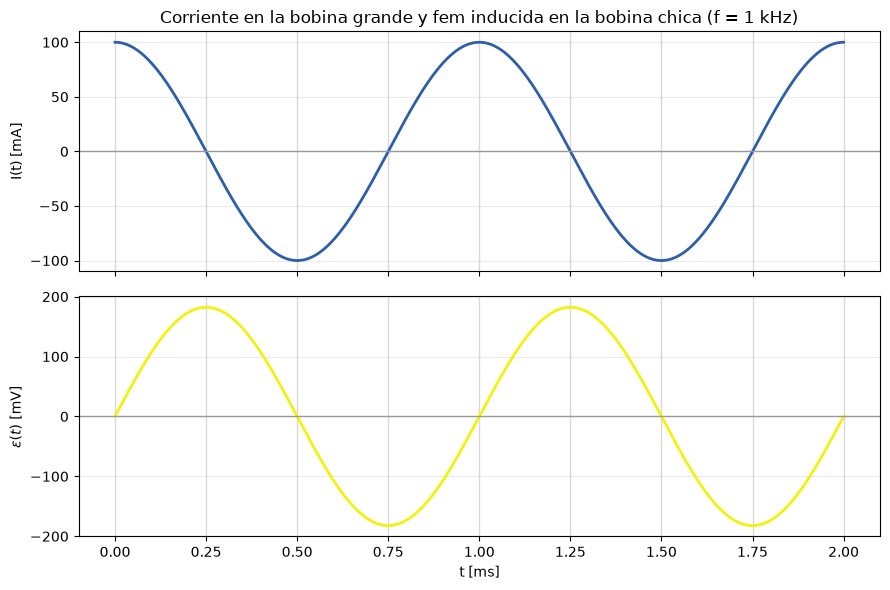

In [2]:
T = 1 / f
t = np.linspace(0, 2 * T, 1000)    # dos períodos

I_t = I0 * np.cos(w * t)
fem_t = k * np.sin(w * t)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True)

ax1.plot(t * 1e3, I_t * 1e3, color="#2E5EAA", linewidth=2)
ax1.set_ylabel("I(t) [mA]")
ax1.set_title(f"Corriente en la bobina grande y fem inducida en la bobina chica (f = {f/1e3:g} kHz)")

ax2.plot(t * 1e3, fem_t * 1e3, color="#F2F20E", linewidth=2)
ax2.set_ylabel(r"$\varepsilon(t)$ [mV]")
ax2.set_xlabel("t [ms]")

for ax in (ax1, ax2):
    ax.axhline(0, color="0.6", linewidth=1)
    for n in range(9):
        ax.axvline(n * T / 4 * 1e3, color="0.9", linewidth=1, zorder=0)
    ax.grid(alpha=0.25)

fig.tight_layout()
plt.show()

* La fem tiene la misma frecuencia que la corriente, pero está **desfasada un cuarto de período** ($90°$): es máxima cuando la corriente pasa por cero, y es cero cuando la corriente es máxima o mínima.
* Esto es lo que dice Faraday: la fem no depende del valor del flujo, sino de **qué tan rápido cambia**. Cuando la corriente está en un máximo, el flujo está "quieto" por un instante (no cambia) y la fem es nula; cuando la corriente pasa por cero, el flujo está cambiando lo más rápido posible y la fem es máxima.
* El signo (ley de Lenz) se ve en que la fem es positiva mientras la corriente baja y negativa mientras sube: siempre se opone al cambio.

### 3.2. Validez de las aproximaciones

En el cálculo de $k$ se hicieron dos aproximaciones.

**Campo uniforme.** Supusimos que el campo es el mismo en toda la superficie de la bobina chica e igual al del centro de la bobina grande. En realidad, dentro del plano de la bobina el campo **crece** al alejarse del centro (cerca del alambre de la bobina es más intenso). El campo exacto en el plano de la bobina, a una distancia $\rho$ del centro, se obtiene integrando Biot-Savart y queda en función de las integrales elípticas $K$ y $E$:

$$B_z(\rho) = \frac{\mu_0 N I}{2\pi}\,\frac{1}{r+\rho}\left[K(m) + \frac{r^2-\rho^2}{(r-\rho)^2}\,E(m)\right], \qquad m = \frac{4r\rho}{(r+\rho)^2}$$

El flujo exacto por vuelta se obtiene sumando el campo sobre anillos de radio $\rho$ y área $2\pi\rho\,d\rho$, desde el centro hasta $b$:

$$\Phi_{exacto} = N_s\int_0^b B_z(\rho)\,2\pi\rho\,d\rho$$

**Radio promedio.** Las vueltas de la bobina chica están repartidas entre el radio interno $a_1 = 10,6\,mm$ y el externo $a_2 = 16,5\,mm$. Lo que importa para el flujo es el **área** de cada vuelta ($\propto a^2$), y el promedio de $a^2$ no es exactamente el cuadrado del promedio de $a$. Si las vueltas están repartidas de forma pareja entre $a_1$ y $a_2$, el área media corresponde a un radio efectivo:

$$b_{ef} = \sqrt{\frac{a_1^2 + a_1 a_2 + a_2^2}{3}}$$

Campo uniforme:
  B en el borde de la bobina chica = 1.014 B0
  k con campo uniforme = 182.2 mV
  k con campo exacto   = 183.4 mV  (+0.7 %)

Radio promedio:
  b promedio = 13.55 mm   b efectivo = 13.66 mm
  k con b efectivo     = 185.0 mV  (+1.6 %)


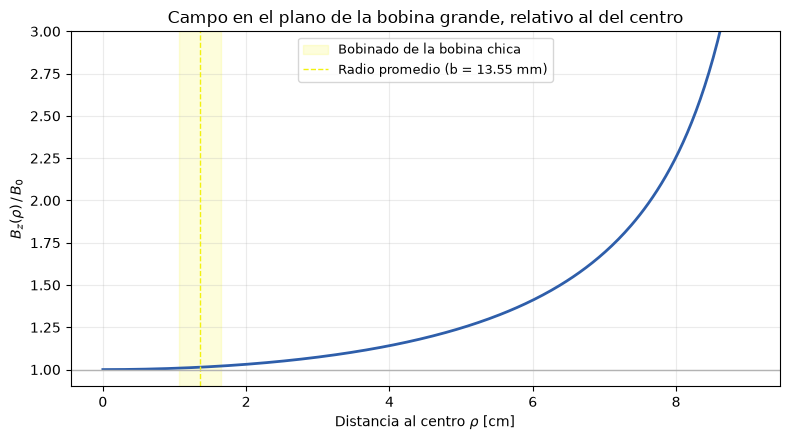

In [3]:
from scipy.special import ellipk, ellipe
from scipy.integrate import quad

def Bz_plano(rho):
    # Campo de la bobina grande en su propio plano, a una distancia rho del centro (amplitud) [T]
    m = 4 * r * rho / (r + rho)**2
    return mu0 * N * I0 / (2 * np.pi) / (r + rho) * (ellipk(m) + (r**2 - rho**2) / (r - rho)**2 * ellipe(m))

Phi0_exacto = N_s * quad(lambda rho: Bz_plano(rho) * 2 * np.pi * rho, 0, b)[0]
k_exacto = Phi0_exacto * w

a1, a2 = D_int / 2, D_ext / 2
b_ef = np.sqrt((a1**2 + a1 * a2 + a2**2) / 3)
k_ef = k * (b_ef / b)**2

print("Campo uniforme:")
print(f"  B en el borde de la bobina chica = {Bz_plano(b) / B0:.3f} B0")
print(f"  k con campo uniforme = {k*1e3:.1f} mV")
print(f"  k con campo exacto   = {k_exacto*1e3:.1f} mV  ({(k_exacto - k) / k * 100:+.1f} %)")
print("\nRadio promedio:")
print(f"  b promedio = {b*1e3:.2f} mm   b efectivo = {b_ef*1e3:.2f} mm")
print(f"  k con b efectivo     = {k_ef*1e3:.1f} mV  ({(k_ef - k) / k * 100:+.1f} %)")

rho = np.linspace(0, 0.9 * r, 300)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(rho * 100, Bz_plano(rho) / B0, color="#2E5EAA", linewidth=2)
ax.axvspan(a1 * 100, a2 * 100, color="#F2F20E", alpha=0.15, label="Bobinado de la bobina chica")
ax.axvline(b * 100, color="#F2F20E", linewidth=1, linestyle="--", label=f"Radio promedio (b = {b*1e3:.2f} mm)")
ax.axhline(1, color="0.7", linewidth=1)
ax.set_xlabel(r"Distancia al centro $\rho$ [cm]")
ax.set_ylabel(r"$B_z(\rho)\,/\,B_0$")
ax.set_title("Campo en el plano de la bobina grande, relativo al del centro")
ax.set_ylim(0.9, 3)
ax.grid(alpha=0.25)
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

Las dos aproximaciones son buenas:

* Como la bobina chica es mucho más chica que la grande ($b/r \approx 0,14$), el campo casi no cambia sobre su superficie ($\approx 1\%$ más en el borde que en el centro), y la aproximación de campo uniforme subestima la fem en menos de un $1\%$. El campo solo crece fuerte cerca del alambre de la bobina grande ($\rho \to r$).
* Usar el diámetro promedio en vez del radio efectivo subestima el área media en un $\approx 1,6\%$.

Ambas diferencias son chicas frente a los errores que podría tener una medición real, así que la expresión $k = \mu_0 N N_s I_0\,\pi b^2\,\omega / 2r$ con el radio promedio es una buena aproximación.

### 3.3. Dependencia con la frecuencia

Como $k$ es proporcional a $\omega = 2\pi f$, la amplitud de la fem crece linealmente con la frecuencia (manteniendo la amplitud de la corriente fija). Sirve como referencia para contrastar con una experiencia real en la que se cambie la frecuencia del generador.

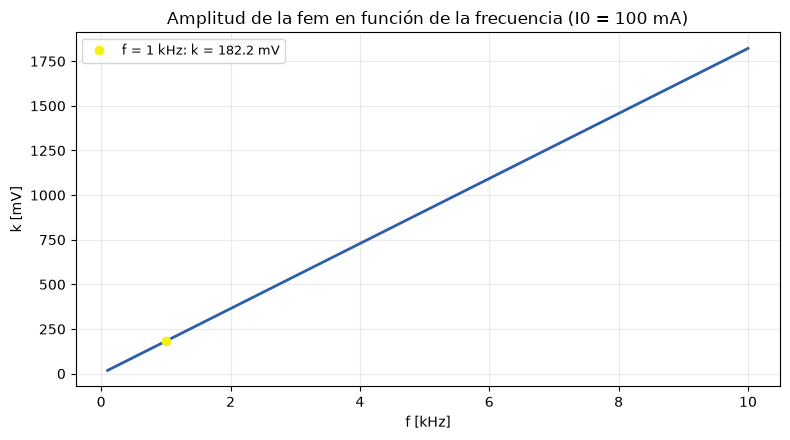

In [4]:
f_rango = np.linspace(100, 10e3, 200)                     # [Hz]
k_rango = mu0 * N * N_s * I0 * np.pi * b**2 * 2 * np.pi * f_rango / (2 * r)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(f_rango / 1e3, k_rango * 1e3, color="#2E5EAA", linewidth=2)
ax.plot(f / 1e3, k * 1e3, "o", color="#F2F20E", label=f"f = {f/1e3:g} kHz: k = {k*1e3:.1f} mV")
ax.set_xlabel("f [kHz]")
ax.set_ylabel("k [mV]")
ax.set_title(f"Amplitud de la fem en función de la frecuencia (I0 = {I0*1e3:g} mA)")
ax.grid(alpha=0.25)
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

## 4. Procedimiento previsto

La experiencia **no llegó a realizarse**. Los pasos previstos eran:

1. Conectar en serie el generador, la bobina grande y la resistencia $R$, con $R$ del lado de la masa del generador.
2. Colocar la bobina chica en el centro de la bobina grande, en el mismo plano.
3. Conectar el canal 1 del osciloscopio sobre $R$ y el canal 2 sobre la bobina chica, con las masas de ambos canales en el mismo punto.
4. Aplicar una señal senoidal de frecuencia $f$, medir la amplitud $V_R$ y calcular la corriente con $I_0 = V_R / R$.
5. Medir la amplitud de la fem y compararla con el valor de $k$ calculado con la corriente medida.
6. Medir el desfasaje a partir de la diferencia de tiempo $\Delta t$ entre las dos señales: $\varphi = 360° \cdot \Delta t / T$.
7. Repetir las mediciones de $V_R$ y de la fem a otras frecuencias.

## 5. Resultados esperados

> La experiencia no pudo realizarse porque la clase se canceló por un problema externo. **Lo que sigue es una predicción teórica, no una medición.**

Como la fem es proporcional a la corriente y $V_R = I_0 R$, la relación entre las dos señales del osciloscopio no depende de cuánta corriente entregue el generador:

$$\frac{k}{V_R} = \frac{\mu_0 N N_s\,\pi b^2\,\omega}{2 r R}$$

En el osciloscopio se esperaba observar:

* **Forma de las señales:** dos senoidales de la misma frecuencia que la del generador, desfasadas $90°$ (un cuarto de período). La tensión en $R$ sigue a la corriente, y la fem es máxima cuando esa tensión pasa por cero.
* **Amplitud:** la amplitud de la fem, proporcional a la de la tensión en $R$ según la relación anterior.
* **Corriente:** la corriente queda limitada por la tensión del generador, la resistencia $R$ y la impedancia de la bobina grande. Por eso $k$ debía calcularse con la corriente medida en $R$.
* **Frecuencia:** $k/V_R$ crece linealmente con $f$. Si se mantiene fija la tensión del generador, $V_R$ baja al aumentar la frecuencia, porque aumenta la reactancia de la bobina grande. Por eso había que medir las dos señales en cada frecuencia.

Las posibles diferencias con la teoría vendrían de la tolerancia de $R$ y de los instrumentos, de la posición de la bobina chica, que podría no quedar centrada o en el mismo plano, y del uso de un radio promedio para su bobinado.

## 6. Conclusiones

Las conclusiones de este trabajo son únicamente teóricas, ya que la experiencia no pudo realizarse:

* A partir de la ley de Faraday-Lenz se obtuvo que la fem inducida en la bobina chica es $\varepsilon(t) = k\,\sin(\omega t)$, con $k = \mu_0 N N_s I_0\,\pi b^2\,\omega / 2r$.
* Con los datos de referencia de la sección 3, la amplitud calculada es $k \approx 182\,mV$.
* La amplitud de la fem es proporcional a la corriente, a la cantidad de vueltas de las dos bobinas, al área de la bobina chica y a la frecuencia.
* La fem está desfasada $90°$ respecto de la corriente, porque depende de qué tan rápido cambia el flujo y no de su valor.
* Las aproximaciones de campo uniforme y de radio promedio cambian el resultado en menos de un $2\%$ cada una.
* La relación $k/V_R$ no depende de la corriente que entregue el generador y es proporcional a la frecuencia, por lo que era la predicción más directa para comparar con una medición.

Estas predicciones quedan planteadas, pero **no fueron verificadas experimentalmente**.